[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AndresOrdonez369/deepLearningWeek1/blob/main/semana2/proyectos/NB03_tu_primera_cnn.ipynb)

# NB03 · Tu primera red convolucional: cómo mira una red una imagen
**Neural Networks: Deep Learning · UIDE · Semana 2 · Tema 1** — Docente: Andrés Ordóñez-Bolaños

**La necesidad:** en la semana 1 las redes recibían **tablas**: las lunas tenían 2 columnas por punto. Ahora la entrada es una **foto**. ¿Sirve la misma red densa? ¿Qué hace distinto una **red convolucional (CNN)**, la arquitectura que domina la visión por computador desde 2012?

Vas a comparar las dos redes con las mismas 70 000 fotos de ropa y vas a ver la idea central de la semana: **cada arquitectura es una suposición sobre cómo están organizados los datos**. La densa supone que todo se relaciona con todo. La CNN supone que **lo cercano importa** y que el mismo patrón (un borde, una esquina) puede aparecer **en cualquier parte** de la foto.

### Cómo usar este Colab (2 minutos)
**Todo el código ya está escrito: tú lees, predices, ejecutas y comparas.** No tienes que programar nada para avanzar.

1. **Archivo → Guardar una copia en Drive.** Así tus cambios quedan guardados.
2. Ejecuta la celda **Configuración** y después avanza en orden con `Shift + Enter`.
3. Cada parte sigue el mismo orden:
   **Qué vas a hacer → la necesidad → ejemplo → el nombre → la fórmula («Léelo así») → Qué hace este código → 🔮 Antes de ejecutar: ¿qué crees que saldrá? → ejecuta → Qué deberías ver → 💭 Para pensar.**
4. En **🔮 Antes de ejecutar** detente cinco segundos y apuesta un resultado. Acertar no importa; **comparar** sí.
5. En **💭 Para pensar** responde con tu pareja y después abre **Ver respuesta**.
6. Las celdas **🧪 Experimenta** son opcionales: cambia **un solo** valor marcado y vuelve a ejecutar.
7. **No tiene nota.** Trabajen en parejas y equivóquense sin miedo.

> **🛟 Si algo falla**
> - `NameError: name 'x' is not defined` → te saltaste una celda de arriba. Usa **Entorno de ejecución → Ejecutar anteriores** (o **Ejecutar todo**).
> - La descarga de las fotos falla (`URL fetch failure`) → espera unos segundos y vuelve a ejecutar la celda de la Parte 0.
> - Un error que menciona `shape` (forma) → la imagen no tiene la forma que la red espera, `(28, 28, 1)`. Vuelve a ejecutar la Parte 0 sin cambios.
> - Entrenar va lento → normal en CPU: cada red tarda menos de un minuto. Si quieres, **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**.
> - Si cambiaste algo y ya no sabes qué: **Entorno de ejecución → Reiniciar y ejecutar todo**.

### Mapa del Colab
| Parte | Qué aprendes | Lámina |
|---|---|---|
| 0 | Una imagen es una tabla de números | 13 |
| 1 | La lupa a mano: un filtro de 3 × 3 con NumPy | 16–17 |
| 2 | La línea base: una red densa | 14, 22 |
| 3 | La CNN en Keras | 19–21 |
| 4 | Mirar adentro: los filtros que aprendió y sus mapas | 18 |
| 5 | Poner a prueba la suposición: mover y mezclar píxeles | 15, 24 |
| 6 | ¿En qué se equivoca? | 24 |
| 🏁 | Resumen · **Para comprobar que entendiste** · **Experimento 3: ¿cuántos filtros?** | 23 |

En clase (lámina 23): prioridad **0, 2, 3 y 5**. Las partes 1, 4 y 6 pueden quedar para casa.

In [1]:
# @title Configuración · ejecuta esta celda primero (no necesitas abrirla)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow info messages
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 2026
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=2, suppress=True, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

# The same colors as the slides: amber = CNN / positive, azure = dense / negative, mint = learned, coral = error
AMBAR, AZUL, MENTA, CORAL, TINTA, LILA = "#E39A12", "#2B8FD6", "#12A37F", "#E0533D", "#1F2A3A", "#8B6FD1"

# The 10 classes of Fashion-MNIST, in Spanish, in the order of the labels 0..9
CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "zapatilla", "bolso", "botín"]

def ver(img, ax, title="", cmap="gray"):
    # Draws a 28 x 28 image (values 0..1 or 0..255) without axes
    ax.imshow(np.squeeze(img), cmap=cmap); ax.set_title(title, fontsize=10); ax.axis("off")

def barras(probs, ax, title=""):
    # Horizontal bars with the 10 probabilities of a softmax; the largest one in amber
    colores = [AMBAR if i == int(np.argmax(probs)) else "#C9D3DE" for i in range(10)]
    ax.barh(CLASES, probs, color=colores); ax.set_xlim(0, 1); ax.invert_yaxis()
    ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=0)
    for i, p in enumerate(probs):
        if p > 0.02: ax.text(p + 0.01, i, f"{p:.0%}", va="center", fontsize=9)

print("Listo. TensorFlow", tf.__version__, "| Keras", keras.__version__)

Listo. TensorFlow 2.21.0 | Keras 3.15.1


---
## 0 · Una imagen es una tabla de números
📽 Lámina 13

**Qué vas a hacer:** cargar 70 000 fotos de ropa y ver que, para la computadora, cada foto es una tabla de números.

**Los datos: Fashion-MNIST** (Zalando, 2017). Son fotos de prendas en blanco y negro, de 28 × 28 píxeles, en **10 clases**: camiseta, pantalón, suéter, vestido, abrigo, sandalia, camisa, zapatilla, bolso y botín. Vienen ya separadas: **60 000 para entrenar** y **10 000 para el examen final** (prueba).

**El nombre:** cada cuadrito de la foto es un **píxel** y guarda un **brillo** entre 0 (negro) y 255 (blanco). Una foto de 28 × 28 son **784 números**.

**Qué hace este código:**
- `keras.datasets.fashion_mnist.load_data()` descarga las fotos (la primera vez tarda unos segundos) y las entrega en dos pares: entrenamiento y prueba.
- `x_train.shape` dice cuántas fotos hay y de qué tamaño; `y_train[:10]` son las primeras 10 etiquetas (números del 0 al 9, que traducimos con `CLASES`).
- Dibuja las 10 primeras fotos con su etiqueta.

🔮 **Antes de ejecutar:** ¿qué forma tendrá `x_train`? Pista: muchas fotos, cada una de 28 × 28.

x_train: (60000, 28, 28) | y_train: (60000,)
x_test:  (10000, 28, 28)  | y_test:  (10000,)
primeras etiquetas: [9 0 0 3 0 2 7 2 5 5] → ['botín', 'camiseta', 'camiseta', 'vestido', 'camiseta', 'suéter', 'zapatilla', 'suéter', 'sandalia', 'sandalia']


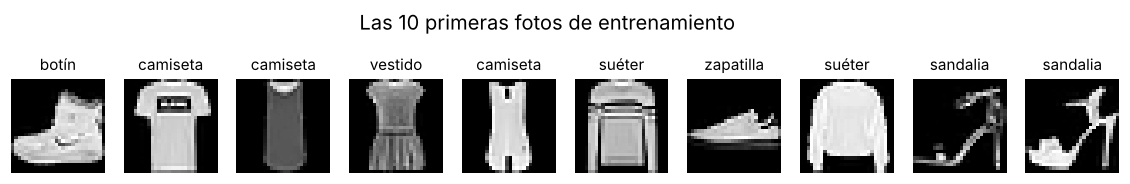

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()   # downloads once

print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_test: ", x_test.shape, " | y_test: ", y_test.shape)
print("primeras etiquetas:", y_train[:10], "→", [CLASES[k] for k in y_train[:10]])

fig, axs = plt.subplots(1, 10, figsize=(13, 1.9))
for k, ax in enumerate(axs):
    ver(x_train[k], ax, CLASES[y_train[k]])
plt.suptitle("Las 10 primeras fotos de entrenamiento", y=1.05); plt.show()

**Qué deberías ver:** `x_train: (60000, 28, 28)` y `x_test: (10000, 28, 28)`: 60 000 fotos para estudiar y 10 000 para el examen, cada una de 28 × 28. Las primeras etiquetas son `[9 0 0 3 0 2 7 2 5 5]`: botín, camiseta, camiseta, vestido, camiseta, suéter, zapatilla, suéter, sandalia, sandalia.

### Los números de una foto
**Qué hace este código:** toma la primera foto de **prueba** (un botín), imprime sus números en un recorte de 8 × 14 píxeles (filas 10 a 17, columnas 8 a 21) y la dibuja con ese recorte marcado.

🔮 **Antes de ejecutar:** en el recorte hay parte del botín y parte del fondo. ¿Qué número tendrá el fondo?

etiqueta: 9 → botín | forma: (28, 28) | mínimo: 0 | máximo: 255
Recorte (filas 10 a 17, columnas 8 a 21):
[[  0   0   0   0   0   4   0  53 129 120 147 175 157 166]
 [  0   0   0   0   2   0  11 137 130 128 160 176 159 167]
 [  2   1   0   3   0   0 115 114 106 137 168 153 156 165]
 [  0   0   3   0   0  89 139  90  94 153 149 131 151 169]
 [  1   0   0   0  98 136 110 109 110 162 135 144 149 159]
 [  0   0  26 108 117  99 111 117 136 156 134 154 154 156]
 [ 53  92 117 111 103 115 129 134 143 154 165 170 154 151]
 [128 123 111 113 118 127 125 139 133 136 160 140 155 161]]


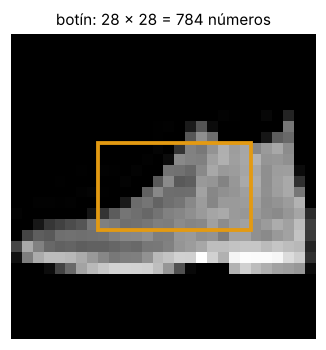

In [3]:
botin = x_test[0]                                  # the first test image: an ankle boot (label 9)
print("etiqueta:", y_test[0], "→", CLASES[y_test[0]], "| forma:", botin.shape, "| mínimo:", botin.min(), "| máximo:", botin.max())
print("Recorte (filas 10 a 17, columnas 8 a 21):")
print(botin[10:18, 8:22])

fig, ax = plt.subplots(figsize=(3.6, 3.6))
ver(botin, ax, "botín: 28 × 28 = 784 números")
ax.add_patch(plt.Rectangle((7.5, 9.5), 14, 8, fill=False, edgecolor=AMBAR, lw=2.5))
plt.show()

**Qué deberías ver:** la forma `(28, 28)`, el mínimo 0 y el máximo 255, y una tabla de números: los **0** son el fondo negro y los números grandes (más de 150) son la parte clara del botín. **La foto es esta tabla**: no hay nada más.

### Prepararla para la red
Dos cambios pequeños antes de entrenar:
1. **Dividir entre 255**, para que cada brillo quede entre 0 y 1 (en la semana 1 vimos que las redes aprenden mejor con números pequeños y parecidos).
2. **Agregar un eje al final** (`[..., None]`): la forma pasa de `(28, 28)` a `(28, 28, 1)`. Ese último **1 es el canal**: las fotos en blanco y negro tienen un canal; las de color tienen 3 (rojo, verde y azul). Las capas convolucionales de Keras esperan ese eje.

**Qué hace este código:** aplica los dos cambios a entrenamiento y prueba e imprime las formas nuevas.

In [4]:
x_train = (x_train / 255.0).astype("float32")[..., None]   # 0..255 -> 0..1, and add the channel axis
x_test = (x_test / 255.0).astype("float32")[..., None]
print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| máximo:", x_train.max())

x_train: (60000, 28, 28, 1) | x_test: (10000, 28, 28, 1) | máximo: 1.0


**Qué deberías ver:** `x_train: (60000, 28, 28, 1)` y `x_test: (10000, 28, 28, 1)`, con máximo 1.0. Léelo así: **(fotos, alto, ancho, canales)**.

### 💭 Para pensar

**1.** ¿Cuántos números tiene una sola foto de Fashion-MNIST? ¿Y una foto de color de 28 × 28?

<details><summary>Ver respuesta</summary>

28 × 28 = **784** en blanco y negro. Con color, 28 × 28 × 3 = **2 352**: un número por píxel y por canal (rojo, verde, azul).
</details>

**2.** Si el fondo vale 0 y la prenda vale cerca de 1 (después de dividir entre 255), ¿dónde están los «bordes» de la prenda?

<details><summary>Ver respuesta</summary>

Donde un número cercano a 0 queda **al lado** de uno cercano a 1: un salto brusco de brillo entre píxeles vecinos. Eso es justo lo que buscará el filtro de la Parte 1.
</details>

---
## 1 · La lupa a mano: un filtro de 3 × 3
📽 Láminas 16–17

**Qué vas a hacer:** pasar una «lupa» de 3 × 3 por toda la foto, como hace una CNN, y ver qué encuentra.

**La necesidad:** para reconocer un botín no hace falta mirar los 784 píxeles a la vez. Primero buscamos cosas **pequeñas y locales**: un borde, una esquina, una línea. Y un borde es un borde **en cualquier parte** de la foto.

**El nombre:** un **filtro** (o *kernel*) es una tablita de 3 × 3 pesos. La **convolución** lo pone sobre cada ventana de 3 × 3 de la foto, multiplica número por número, suma los 9 productos y anota el resultado. El resultado de recorrer toda la foto es un **mapa de activación**: dice **dónde** encontró el patrón.

$$\text{salida}[i, j] = \sum_{a=0}^{2}\sum_{b=0}^{2} \text{foto}[i+a,\ j+b] \cdot \text{filtro}[a, b]$$

**Léelo así:** "para cada posición $(i, j)$, toma la ventana de 3 × 3 que empieza ahí, multiplica cada píxel por el peso del filtro que le queda encima y suma los 9 productos". Es la neurona de la semana 1 (suma de datos por pesos), pero mirando solo 9 píxeles vecinos.

### Ejemplo: el filtro de borde vertical
$$\text{filtro} = \begin{bmatrix}-1 & 0 & 1\\ -1 & 0 & 1\\ -1 & 0 & 1\end{bmatrix}$$

Resta la columna de la izquierda y suma la de la derecha. Si los dos lados tienen el mismo brillo, da **0**. Si a la izquierda está oscuro y a la derecha claro, da un número **grande y positivo**; al revés, **negativo**.

**Qué hace este código:**
- `convolucion(foto, filtro)` recorre las posiciones con dos ciclos `for` y en cada una suma `ventana * filtro`. Como la ventana no puede salirse de la foto, la salida mide **26 × 26** (28 − 3 + 1).
- Aplica el filtro vertical y uno horizontal (el mismo, girado) al botín y dibuja los tres.

🔮 **Antes de ejecutar:** el botín tiene bordes de todo tipo. ¿Dónde se encenderá el filtro vertical: en la suela o en los costados?

forma de la foto: (28, 28) → forma del mapa: (26, 26)
mapa vertical:   de -1.95 a 1.32
mapa horizontal: de -2.96 a 1.98


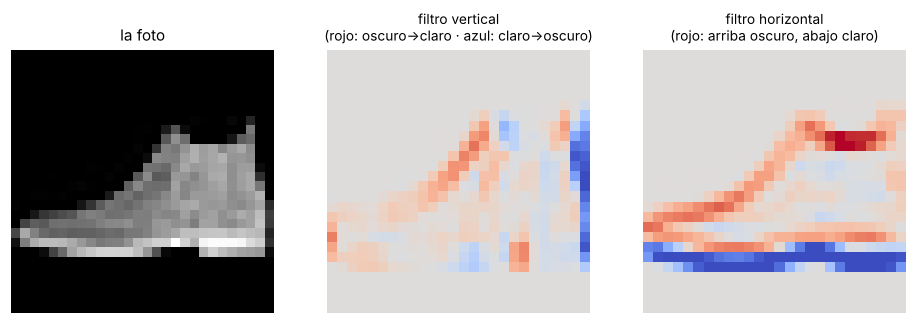

In [5]:
def convolucion(foto, filtro):
    # Slides a 3x3 filter over the image; each output number is the sum of (window * filter)
    alto, ancho = foto.shape
    salida = np.zeros((alto - 2, ancho - 2))
    for i in range(alto - 2):
        for j in range(ancho - 2):
            ventana = foto[i:i + 3, j:j + 3]          # the 3x3 window under the magnifying glass
            salida[i, j] = np.sum(ventana * filtro)   # multiply number by number and add the 9 products
    return salida

borde_vertical = np.array([[-1, 0, 1],
                           [-1, 0, 1],
                           [-1, 0, 1]])
borde_horizontal = borde_vertical.T                  # the same filter, rotated: top vs bottom

foto = x_test[0, :, :, 0]                            # the ankle boot, values 0..1
mapa_v = convolucion(foto, borde_vertical)
mapa_h = convolucion(foto, borde_horizontal)
print("forma de la foto:", foto.shape, "→ forma del mapa:", mapa_v.shape)
print(f"mapa vertical:   de {mapa_v.min():.2f} a {mapa_v.max():.2f}")
print(f"mapa horizontal: de {mapa_h.min():.2f} a {mapa_h.max():.2f}")

fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.6))
ver(foto, axs[0], "la foto")
lim = np.abs(mapa_v).max()
axs[1].imshow(mapa_v, cmap="coolwarm", vmin=-lim, vmax=lim); axs[1].set_title("filtro vertical\n(rojo: oscuro→claro · azul: claro→oscuro)", fontsize=9); axs[1].axis("off")
axs[2].imshow(mapa_h, cmap="coolwarm", vmin=-lim, vmax=lim); axs[2].set_title("filtro horizontal\n(rojo: arriba oscuro, abajo claro)", fontsize=9); axs[2].axis("off")
plt.show()

**Qué deberías ver:** la foto de 28 × 28 se convierte en un mapa de **26 × 26**. El mapa vertical se enciende en los **bordes de los lados** del botín: rojo donde se pasa de oscuro a claro y azul donde se pasa de claro a oscuro. El horizontal se enciende en los bordes de **arriba y abajo** (la suela, la caña). Donde todo es fondo, los dos dan **0**.

### Una ventana, con los números
**Qué hace este código:** toma la ventana de 3 × 3 de las filas 11 a 13 y columnas 13 a 15: el borde izquierdo de la caña del botín (está dentro del recuadro ámbar de la Parte 0). La multiplica por el filtro vertical y muestra los 9 productos y su suma.

🔮 **Antes de ejecutar:** en esa ventana, ¿la columna de la derecha será más clara o más oscura que la de la izquierda?

In [6]:
i, j = 11, 13
ventana = foto[i:i + 3, j:j + 3]
print("ventana de la foto:\n", ventana)
print("filtro:\n", borde_vertical)
print("productos (ventana × filtro):\n", ventana * borde_vertical)
print(f"suma = {np.sum(ventana * borde_vertical):.2f}   ← lo que el mapa anota en la posición ({i}, {j})")

ventana de la foto:
 [[0.   0.04 0.54]
 [0.   0.45 0.45]
 [0.35 0.55 0.35]]
filtro:
 [[-1  0  1]
 [-1  0  1]
 [-1  0  1]]
productos (ventana × filtro):
 [[-0.    0.    0.54]
 [-0.    0.    0.45]
 [-0.35  0.    0.35]]
suma = 0.99   ← lo que el mapa anota en la posición (11, 13)


**Qué deberías ver:** la columna de la izquierda es casi negra (0, 0 y 0.35) y la de la derecha es clara (0.54, 0.45 y 0.35). La del medio se multiplica por 0 y no cuenta. La suma es (0.54 + 0.45 + 0.35) − (0 + 0 + 0.35) ≈ **+0.99**: positiva, así que ahí hay un borde «oscuro → claro», y el mapa vertical lo pinta de rojo.

### 💭 Para pensar

**1.** ¿Qué devuelve el filtro vertical sobre una zona donde los 9 píxeles valen lo mismo, por ejemplo 0.5?

<details><summary>Ver respuesta</summary>

**0**: la columna de la izquierda (×−1) y la de la derecha (×+1) se cancelan. El filtro solo responde a **cambios** de brillo de izquierda a derecha.
</details>

**2.** ¿Cuántos pesos tiene el filtro? ¿Cambia ese número si la foto fuera de 1 000 × 1 000?

<details><summary>Ver respuesta</summary>

**9** (más un sesgo cuando lo usa una red). No cambia: la misma lupa recorre la foto, sea del tamaño que sea. Esa es la idea de **compartir pesos** de la Parte 3.
</details>

**3.** En una CNN, ¿quién elige los números del filtro?

<details><summary>Ver respuesta</summary>

**Nadie a mano**: los aprende la red con el descenso de gradiente de la semana 1, igual que los pesos de una neurona. Aquí los escribimos nosotros solo para ver qué hace un filtro. En la Parte 4 verás los que aprendió.
</details>

---
## 2 · La línea base: una red densa
📽 Láminas 14, 22

**Qué vas a hacer:** entrenar la red de la semana 1 con las fotos, para tener contra qué comparar.

**La idea:** una red densa recibe una **fila** de números. Así que **aplanamos** la foto: las 28 filas, una detrás de otra, forman una fila de 784 números (`Flatten`). Después, una capa oculta de 128 neuronas conectadas con todo y una salida.

**De sí o no a 10 clases: softmax.** En la semana 1 la salida era **una** neurona con sigmoide (probabilidad de «sí»). Ahora hay **10 clases**, así que la salida tiene **10 neuronas** con **softmax**: convierte sus 10 puntajes en **10 probabilidades que suman 1**.

$$p_k = \frac{e^{z_k}}{e^{z_0} + e^{z_1} + \dots + e^{z_9}}$$

**Léelo así:** "la probabilidad de la clase $k$ es su puntaje convertido en positivo ($e^{z_k}$), dividido entre la suma de todos". El puntaje más grande se lleva la probabilidad más grande.

**La pérdida:** `sparse_categorical_crossentropy` es la entropía cruzada de la semana 1 para muchas clases: $-\log$ de la probabilidad que le dio a la clase correcta. *Sparse* solo significa que la etiqueta viene como un número del 0 al 9.

**Qué hace este código:**
- `red_densa()` arma: `Input(28, 28, 1)` → `Flatten` (784 números) → `Dense(128, relu)` → `Dense(10, softmax)`.
- `entrenar()` compila (Adam, la entropía cruzada y la exactitud) y entrena **5 épocas** con lotes de 128 fotos, separando el 10 % como **validación** (el simulacro). Devuelve la historia y los segundos que tardó.
- `keras.utils.set_random_seed(SEED)` justo antes de crear la red: así todos obtenemos los mismos pesos iniciales.

🔮 **Antes de ejecutar:** ¿cuántos parámetros tendrá la red? Pista: cada una de las 128 neuronas tiene un peso por cada uno de los 784 píxeles, más su sesgo.

In [7]:
def red_densa():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Flatten(),                          # 28 x 28 -> one row of 784 numbers
        layers.Dense(128, activation="relu"),      # 128 neurons connected to every pixel
        layers.Dense(10, activation="softmax"),    # 10 probabilities that add up to 1
    ])

def entrenar(model, X, y):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t = time.time()
    h = model.fit(X, y, epochs=5, batch_size=128, validation_split=0.1, verbose=2)   # one line per epoch
    return h, time.time() - t

keras.utils.set_random_seed(SEED)
densa = red_densa()
densa.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

**Qué deberías ver:** `Flatten` con salida de 784; la capa de 128 neuronas con **100 480** parámetros (784 × 128 + 128); la salida con **1 290** (128 × 10 + 10). **Total: 101 770 parámetros.** Casi todos están en la primera capa: cada neurona mira **cada** píxel.

**Ahora a entrenar.** **Qué hace este código:** entrena la red densa e imprime una línea por época (pérdida y exactitud de entrenamiento y de validación).

🔮 **Antes de ejecutar:** con 10 clases, adivinar al azar da 10 %. ¿Qué exactitud crees que tendrá después de 5 épocas?

In [8]:
hist_densa, seg_densa = entrenar(densa, x_train, y_train)
_, acc_densa = densa.evaluate(x_test, y_test, verbose=0)    # the final exam: 10 000 photos it never saw
print(f"\nRed densa · {densa.count_params():,} parámetros · {seg_densa:.0f} s · exactitud en prueba: {acc_densa:.1%}")

Epoch 1/5


422/422 - 3s - 7ms/step - accuracy: 0.8041 - loss: 0.5717 - val_accuracy: 0.8442 - val_loss: 0.4436


Epoch 2/5


422/422 - 1s - 3ms/step - accuracy: 0.8549 - loss: 0.4157 - val_accuracy: 0.8617 - val_loss: 0.3925


Epoch 3/5


422/422 - 1s - 3ms/step - accuracy: 0.8678 - loss: 0.3755 - val_accuracy: 0.8697 - val_loss: 0.3700


Epoch 4/5


422/422 - 1s - 3ms/step - accuracy: 0.8765 - loss: 0.3492 - val_accuracy: 0.8747 - val_loss: 0.3556


Epoch 5/5


422/422 - 1s - 3ms/step - accuracy: 0.8826 - loss: 0.3293 - val_accuracy: 0.8778 - val_loss: 0.3463



Red densa · 101,770 parámetros · 10 s · exactitud en prueba: 86.7%


**Qué deberías ver:** 5 líneas, una por época, con la pérdida bajando (de ≈ 0.57 a ≈ 0.33) y la exactitud de validación subiendo hasta ≈ **88 %**. En el examen final, alrededor de **86.7 %**. Nada mal: la red de la semana 1 ya reconoce ropa.

### 💭 Para pensar

**1.** ¿Por qué la salida tiene 10 neuronas con softmax y no una con sigmoide, como en la semana 1?

<details><summary>Ver respuesta</summary>

Porque ahora hay **10 respuestas posibles**. La sigmoide da la probabilidad de un solo «sí»; softmax reparte la probabilidad entre las 10 clases y **suman 1**.
</details>

**2.** Después de `Flatten`, ¿la red sabe que el píxel 30 está justo debajo del píxel 2?

<details><summary>Ver respuesta</summary>

**No.** Para la densa, la entrada es una fila de 784 números sin vecinos: el píxel 30 es tan «lejano» del 2 como el 700. Esa es su suposición: todo se relaciona con todo. En la Parte 5 lo comprobamos.
</details>

---
## 3 · La CNN en Keras
📽 Láminas 19–21

**Qué vas a hacer:** construir una red convolucional pequeña y compararla con la densa.

**Las piezas nuevas:**
- **`Conv2D(16, 3)`**: 16 filtros de 3 × 3 que recorren la foto (como en la Parte 1, pero **aprendidos**). Cada filtro produce su propio mapa: la salida son **16 mapas**. Cada filtro tiene 9 pesos + 1 sesgo = **10 parámetros**, y **los usa en toda la foto**: eso es **compartir pesos**.
- **`MaxPooling2D(2)`**: de cada ventana de 2 × 2 se queda con el número **más grande**. Reduce el mapa a la mitad (26 → 13) y conserva lo más fuerte, como resumir un párrafo en su frase más importante.
- Una segunda pareja `Conv2D(32, 3)` + `MaxPooling2D(2)` combina los 16 mapas en 32 patrones más grandes (bordes → partes de prendas).
- Al final, `Flatten` + `Dense(10, softmax)`, como en la densa.

**Las formas, paso a paso:**

| Capa | Forma de la salida | Parámetros | Léelo así |
|---|---|---|---|
| Entrada | 28 × 28 × 1 | 0 | la foto |
| Conv2D(16, 3) | 26 × 26 × 16 | 16 × (3·3·1 + 1) = **160** | 16 mapas de 26 × 26 |
| MaxPooling2D(2) | 13 × 13 × 16 | 0 | la mitad de alto y de ancho |
| Conv2D(32, 3) | 11 × 11 × 32 | 32 × (3·3·16 + 1) = **4 640** | cada filtro mira los 16 mapas a la vez |
| MaxPooling2D(2) | 5 × 5 × 32 | 0 | otra vez la mitad (se redondea hacia abajo) |
| Flatten | 800 | 0 | 5 · 5 · 32 = 800 números |
| Dense(10, softmax) | 10 | 800 × 10 + 10 = **8 010** | las 10 probabilidades |

**Qué hace este código:** `red_cnn()` arma esas capas en orden con `Sequential` y `summary()` las muestra con sus formas y parámetros.

🔮 **Antes de ejecutar:** suma la columna de parámetros. ¿La CNN tendrá más o menos parámetros que la densa (101 770)?

In [9]:
def red_cnn():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, 3, activation="relu"),   # 16 learned 3x3 filters -> 16 maps of 26x26
        layers.MaxPooling2D(2),                    # keep the strongest of each 2x2 -> 13x13
        layers.Conv2D(32, 3, activation="relu"),   # 32 filters that look at the 16 maps -> 11x11
        layers.MaxPooling2D(2),                    # -> 5x5
        layers.Flatten(),                          # 5 * 5 * 32 = 800 numbers
        layers.Dense(10, activation="softmax"),    # 10 probabilities
    ])

keras.utils.set_random_seed(SEED)
cnn = red_cnn()
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         8,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,810 (50.04 KB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 0 (0.00 B)

**Qué deberías ver:** las formas de la tabla (26, 26, 16) → (13, 13, 16) → (11, 11, 32) → (5, 5, 32) → 800 → 10, y **12 810 parámetros en total**: alrededor de **8 veces menos** que la densa. La razón: un filtro de 10 parámetros sirve para **toda** la foto, en vez de un peso por píxel para cada neurona.

**Ahora a entrenar, con las mismas reglas que la densa.** **Qué hace este código:** la misma función `entrenar` (5 épocas, lotes de 128, 10 % de validación) y el mismo examen final.

🔮 **Antes de ejecutar:** con 8 veces menos parámetros, ¿acertará más o menos que la densa?

In [10]:
hist_cnn, seg_cnn = entrenar(cnn, x_train, y_train)
_, acc_cnn = cnn.evaluate(x_test, y_test, verbose=0)
print(f"\nCNN · {cnn.count_params():,} parámetros · {seg_cnn:.0f} s · exactitud en prueba: {acc_cnn:.1%}")
print(f"Densa · {densa.count_params():,} parámetros · {seg_densa:.0f} s · exactitud en prueba: {acc_densa:.1%}")

Epoch 1/5


422/422 - 5s - 11ms/step - accuracy: 0.7581 - loss: 0.6982 - val_accuracy: 0.8265 - val_loss: 0.4732


Epoch 2/5


422/422 - 3s - 8ms/step - accuracy: 0.8460 - loss: 0.4329 - val_accuracy: 0.8558 - val_loss: 0.4017


Epoch 3/5


422/422 - 4s - 8ms/step - accuracy: 0.8649 - loss: 0.3830 - val_accuracy: 0.8708 - val_loss: 0.3656


Epoch 4/5


422/422 - 5s - 13ms/step - accuracy: 0.8747 - loss: 0.3540 - val_accuracy: 0.8792 - val_loss: 0.3452


Epoch 5/5


422/422 - 4s - 9ms/step - accuracy: 0.8809 - loss: 0.3344 - val_accuracy: 0.8847 - val_loss: 0.3315



CNN · 12,810 parámetros · 23 s · exactitud en prueba: 87.7%
Densa · 101,770 parámetros · 10 s · exactitud en prueba: 86.7%


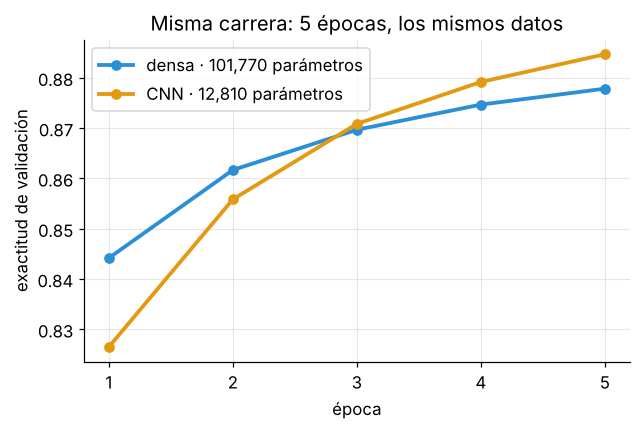

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
epocas = range(1, 6)
ax.plot(epocas, hist_densa.history["val_accuracy"], "o-", color=AZUL, lw=2.5, label=f"densa · {densa.count_params():,} parámetros")
ax.plot(epocas, hist_cnn.history["val_accuracy"], "o-", color=AMBAR, lw=2.5, label=f"CNN · {cnn.count_params():,} parámetros")
ax.set_xlabel("época"); ax.set_ylabel("exactitud de validación"); ax.set_xticks(list(epocas))
ax.set_title("Misma carrera: 5 épocas, los mismos datos"); ax.legend(); plt.show()

**Qué deberías ver:** la CNN llega a alrededor de **87.7 %** en el examen final, un poco más que la densa (**86.7 %**), con **12 810** parámetros contra **101 770**. En la gráfica, la CNN empieza un poco más abajo (época 1) y termina arriba. Tarda un poco más por época (cada filtro recorre toda la foto), pero aprende **mucho menos números**.

Un punto de diferencia en exactitud parece poco. Lo importante viene en la Parte 5: **qué pasa cuando la foto cambia un poco**.

### 💭 Para pensar

**1.** ¿Por qué la primera capa convolucional tiene solo 160 parámetros, si produce 16 mapas de 26 × 26 = 10 816 números?

<details><summary>Ver respuesta</summary>

Porque cada uno de los 16 filtros tiene **10 parámetros** (9 pesos + 1 sesgo) y se **reutiliza** en las 676 posiciones de la foto. Muchos números de salida, pocos números que aprender: **compartir pesos**.
</details>

**2.** ¿Qué pasaría con la forma si quitáramos los dos `MaxPooling2D`?

<details><summary>Ver respuesta</summary>

Los mapas no se reducirían: 26 × 26 × 16 → 24 × 24 × 32, y `Flatten` daría 18 432 números. La capa final tendría 184 330 parámetros: el pooling, además de resumir, **ahorra parámetros**.
</details>

**3.** ¿Son comparables las dos redes? ¿Qué hicimos para que la comparación fuera justa?

<details><summary>Ver respuesta</summary>

Sí: los **mismos datos**, la misma división de validación, el mismo optimizador, las mismas **5 épocas** y el mismo examen final. Es la lección de la lectura de la semana 1 (y de esta semana): antes de declarar un ganador, que todos corran **la misma carrera**.
</details>

---
## 4 · Mirar adentro: lo que aprendió la red
📽 Lámina 18

**Qué vas a hacer:** ver los 16 filtros que la CNN aprendió sola y los mapas que producen sobre el botín.

**Qué hace este código:**
- `cnn.layers[0].get_weights()` devuelve los pesos de la primera capa: una tabla de forma `(3, 3, 1, 16)` (16 filtros de 3 × 3) y sus 16 sesgos.
- `keras.Model(cnn.inputs, cnn.layers[0].output)` arma una «red recortada» que se detiene en la primera capa: con ella vemos los 16 mapas del botín (ya con ReLU, así que solo hay valores ≥ 0).
- Dibuja los 16 filtros (rojo = peso positivo, azul = negativo) y, debajo de cada uno, su mapa.

🔮 **Antes de ejecutar:** ¿crees que alguno se parecerá al filtro de borde vertical de la Parte 1?

forma de los filtros: (3, 3, 1, 16) | forma de los sesgos: (16,)


forma de los mapas: (26, 26, 16)


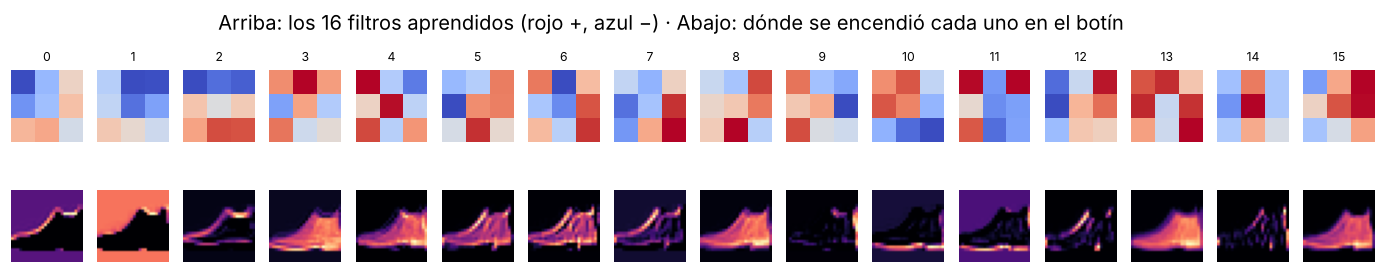

In [12]:
W1, b1 = cnn.layers[0].get_weights()
print("forma de los filtros:", W1.shape, "| forma de los sesgos:", b1.shape)

primera_capa = keras.Model(cnn.inputs, cnn.layers[0].output)      # a network cut after the first layer
mapas = primera_capa.predict(x_test[:1], verbose=0)[0]              # the 16 maps of the ankle boot
print("forma de los mapas:", mapas.shape)

fig, axs = plt.subplots(2, 16, figsize=(16, 2.6))
for f in range(16):
    lim = np.abs(W1[:, :, 0, f]).max()                                # each filter with its own color scale
    axs[0, f].imshow(W1[:, :, 0, f], cmap="coolwarm", vmin=-lim, vmax=lim); axs[0, f].axis("off"); axs[0, f].set_title(f"{f}", fontsize=8)
    axs[1, f].imshow(mapas[:, :, f], cmap="magma"); axs[1, f].axis("off")
plt.suptitle("Arriba: los 16 filtros aprendidos (rojo +, azul −) · Abajo: dónde se encendió cada uno en el botín", y=1.04)
plt.show()

**Qué deberías ver:** filtros de forma `(3, 3, 1, 16)` y mapas de forma `(26, 26, 16)`. Varios filtros tienen una mitad roja y otra azul: son **detectores de bordes** (verticales, horizontales o diagonales), parecidos al que escribimos a mano. Otros responden a toda la prenda (zonas claras) y un par se enciende en el **fondo** (detectan lo oscuro). Nadie se los enseñó: salieron del descenso de gradiente.

### Una prenda, dos redes: las probabilidades
**Qué hace este código:** busca la primera **camisa** del examen final y muestra las 10 probabilidades (softmax) que le dan la densa y la CNN.

🔮 **Antes de ejecutar:** una camisa se parece a una camiseta y a un suéter. ¿Estarán seguras las dos redes?

suma de las probabilidades de la CNN: 1.0


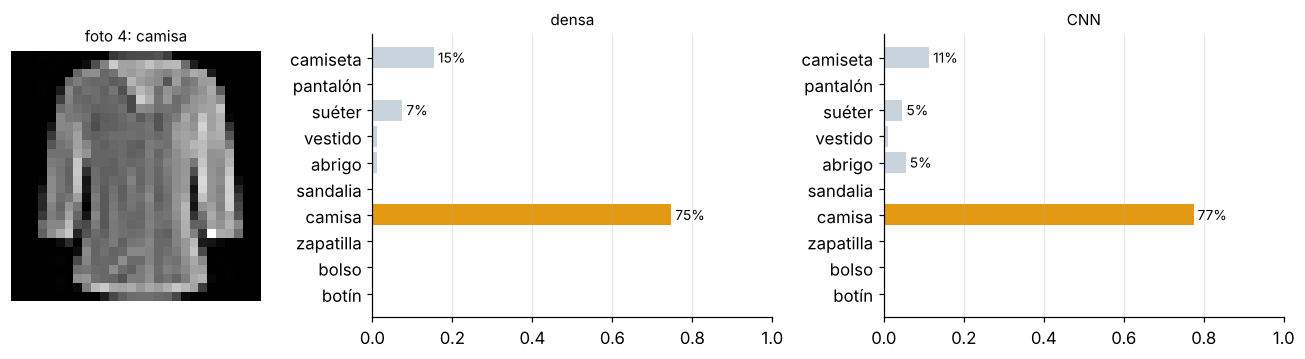

In [13]:
k = int(np.where(y_test == 6)[0][0])                 # the first shirt ("camisa", label 6) of the test set
p_densa = densa.predict(x_test[k:k + 1], verbose=0)[0]
p_cnn = cnn.predict(x_test[k:k + 1], verbose=0)[0]
print("suma de las probabilidades de la CNN:", round(float(p_cnn.sum()), 4))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
ver(x_test[k], axs[0], f"foto {k}: {CLASES[y_test[k]]}")
barras(p_densa, axs[1], "densa"); barras(p_cnn, axs[2], "CNN")
plt.tight_layout(); plt.show()

**Qué deberías ver:** las probabilidades de cada red **suman 1**. Las dos eligen **camisa**: la densa con alrededor de **75 %** y la CNN con alrededor de **77 %**, y las dos dejan algo para camiseta, suéter y abrigo. Dudan entre prendas que se parecen, igual que dudaría una persona.

### 💭 Para pensar

**1.** ¿Por qué ningún mapa de activación tiene valores negativos?

<details><summary>Ver respuesta</summary>

Porque la capa usa **ReLU**: todo lo negativo se vuelve 0 (la válvula de la semana 1). El mapa solo muestra **dónde** el filtro encontró su patrón.
</details>

**2.** La CNN dijo 77 % camisa, 11 % camiseta, 5 % suéter y 5 % abrigo. ¿Cuánto suman las otras 6 clases?

<details><summary>Ver respuesta</summary>

Alrededor de **2 %**: las 10 probabilidades de softmax siempre suman **100 %**.
</details>

---
## 5 · Poner a prueba la suposición
📽 Láminas 15, 24

**Qué vas a hacer:** dos pruebas pequeñas que muestran **qué supone cada red** sobre las fotos.

### Prueba 1: mover la prenda 2 píxeles
**La necesidad:** en la vida real la prenda no siempre está centrada. Una persona la reconoce igual si se corre un poquito. ¿Y las redes?

**Qué hace este código:**
- `mover(X, px)` corre todas las fotos `px` píxeles a la derecha (lo que se sale se pierde; a la izquierda entra fondo negro).
- Evalúa las dos redes **ya entrenadas** con las fotos movidas 0, 1, 2, 3 y 4 píxeles. No se entrena nada nuevo.

🔮 **Antes de ejecutar:** con 2 píxeles (menos del 10 % del ancho), ¿cuál red sufre más?

densa  0 px: 86.7% · 1 px: 77.8% · 2 px: 56.5% · 3 px: 32.3% · 4 px: 22.4%
CNN    0 px: 87.7% · 1 px: 84.4% · 2 px: 75.2% · 3 px: 50.9% · 4 px: 28.2%


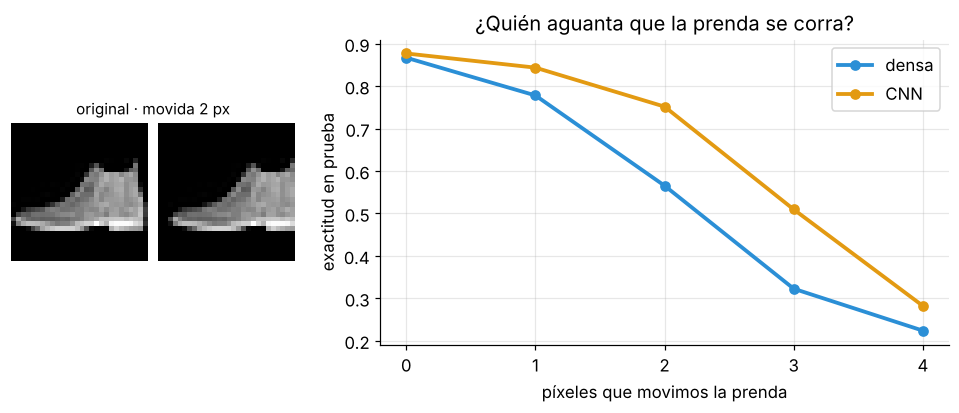

In [14]:
def mover(X, px):
    # Shifts every image px pixels to the right; black background enters on the left
    out = np.zeros_like(X)
    out[:, :, px:, :] = X[:, :, :-px, :]
    return out

resultados = {"densa": [acc_densa], "CNN": [acc_cnn]}
for px in (1, 2, 3, 4):
    resultados["densa"].append(densa.evaluate(mover(x_test, px), y_test, verbose=0)[1])
    resultados["CNN"].append(cnn.evaluate(mover(x_test, px), y_test, verbose=0)[1])
for nombre, accs in resultados.items():
    print(f"{nombre:6s}", " · ".join(f"{px} px: {a:.1%}" for px, a in enumerate(accs)))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
ver(np.hstack([x_test[0, :, :, 0], np.ones((28, 2)), mover(x_test[:1], 2)[0, :, :, 0]]), axs[0], "original · movida 2 px")
axs[1].plot(range(5), resultados["densa"], "o-", color=AZUL, lw=2.5, label="densa")
axs[1].plot(range(5), resultados["CNN"], "o-", color=AMBAR, lw=2.5, label="CNN")
axs[1].set_xlabel("píxeles que movimos la prenda"); axs[1].set_ylabel("exactitud en prueba"); axs[1].set_xticks(range(5))
axs[1].set_title("¿Quién aguanta que la prenda se corra?"); axs[1].legend(); plt.show()

**Qué deberías ver:** con **2 píxeles**, la densa cae de 86.7 % a alrededor de **56.5 %**, mientras la CNN aguanta alrededor de **75.2 %**. Con 1 píxel: 77.8 % contra 84.4 %. Con 4 píxeles **las dos se caen** (alrededor de 22 % y 28 %).

**Léelo así:** para la densa, mover la prenda es cambiar **qué píxel** recibe cada peso: es otra foto. La CNN busca **el mismo borde en cualquier parte**, y el pooling tolera corrimientos pequeños. Pero no es magia: con 4 píxeles también falla. En la semana 3 veremos cómo hacerla más robusta (por ejemplo, entrenando con fotos movidas a propósito).

### Prueba 2: mezclar los píxeles
**La necesidad:** si la densa de verdad **no usa** la vecindad, debería darle igual que mezclemos los píxeles… siempre que los mezclemos **igual en todas las fotos**.

**Qué hace este código:**
- `perm` es un orden al azar de los 784 píxeles (el mismo para todas las fotos).
- `mezclar(X)` reordena los píxeles de cada foto según `perm`. Para nosotros, la foto se vuelve ruido.
- Entrena **dos redes nuevas** (una densa y una CNN, mismas reglas) con las fotos mezcladas y las evalúa con el examen mezclado.

🔮 **Antes de ejecutar:** nosotros ya no reconocemos nada. ¿Cuál de las dos redes notará la diferencia?

Epoch 1/5


422/422 - 2s - 4ms/step - accuracy: 0.8034 - loss: 0.5735 - val_accuracy: 0.8432 - val_loss: 0.4421


Epoch 2/5


422/422 - 2s - 6ms/step - accuracy: 0.8548 - loss: 0.4181 - val_accuracy: 0.8617 - val_loss: 0.3912


Epoch 3/5


422/422 - 1s - 3ms/step - accuracy: 0.8677 - loss: 0.3782 - val_accuracy: 0.8675 - val_loss: 0.3708


... (11 outputs left out)

422/422 - 5s - 12ms/step - accuracy: 0.8574 - loss: 0.4052 - val_accuracy: 0.8507 - val_loss: 0.4005


Epoch 5/5


422/422 - 4s - 9ms/step - accuracy: 0.8660 - loss: 0.3808 - val_accuracy: 0.8562 - val_loss: 0.3846



Densa · original 86.7% → píxeles mezclados 87.2%
CNN   · original 87.7% → píxeles mezclados 85.2%


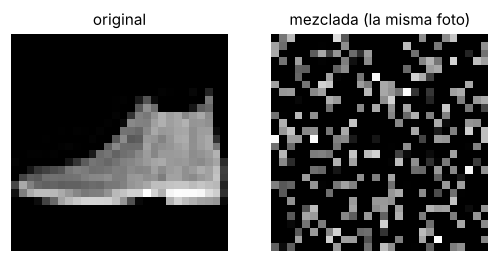

In [15]:
perm = np.random.default_rng(SEED).permutation(28 * 28)           # one fixed shuffle of the 784 pixels
mezclar = lambda X: X.reshape(len(X), -1)[:, perm].reshape(X.shape)
xm_train, xm_test = mezclar(x_train), mezclar(x_test)

keras.utils.set_random_seed(SEED); densa_m = red_densa(); entrenar(densa_m, xm_train, y_train)
keras.utils.set_random_seed(SEED); cnn_m = red_cnn(); entrenar(cnn_m, xm_train, y_train)
acc_densa_m = densa_m.evaluate(xm_test, y_test, verbose=0)[1]
acc_cnn_m = cnn_m.evaluate(xm_test, y_test, verbose=0)[1]
print(f"\nDensa · original {acc_densa:.1%} → píxeles mezclados {acc_densa_m:.1%}")
print(f"CNN   · original {acc_cnn:.1%} → píxeles mezclados {acc_cnn_m:.1%}")

fig, axs = plt.subplots(1, 2, figsize=(5.6, 2.9))
ver(x_test[0], axs[0], "original"); ver(xm_test[0], axs[1], "mezclada (la misma foto)"); plt.show()

**Qué deberías ver:** la densa da **lo mismo** (alrededor de **87.2 %** contra 86.7 %: la diferencia es ruido). La CNN **baja** (alrededor de **85.2 %** contra 87.7 %). La foto mezclada es ruido para nosotros, pero para la densa es exactamente el mismo problema.

**Léelo así:** la densa **nunca usó** qué píxel está al lado de cuál: su suposición es «todo con todo». La CNN sí lo usa: su suposición es «lo cercano importa». Cuando la suposición se rompe (al mezclar, los vecinos ya no son vecinos), la CNN pierde su ventaja. **Cada arquitectura es una suposición sobre los datos.**

### 💭 Para pensar

**1.** ¿Por qué la densa ignora la mezcla de píxeles?

<details><summary>Ver respuesta</summary>

Porque cada neurona tiene **un peso por píxel** y no le importa dónde está ese píxel: reordenar las entradas solo reordena qué peso aprende cada una. El problema es idéntico.
</details>

**2.** Si tus datos fueran una **tabla** de una cooperativa (ingreso, antigüedad, atrasos…), ¿tendría sentido usar una CNN?

<details><summary>Ver respuesta</summary>

En general **no**: en una tabla, la columna «ingreso» no es «vecina» de «antigüedad» de ninguna forma útil; el orden de las columnas es arbitrario. La suposición de la CNN no se cumple, y una densa es la elección natural.
</details>

---
## 6 · ¿En qué se equivoca?
📽 Lámina 24

**Qué vas a hacer:** mirar los errores de la CNN, no solo su exactitud (como la matriz de confusión de la semana 1, ahora con 10 clases).

**Qué hace este código:**
- Predice las 10 000 fotos de prueba y arma la **matriz de confusión**: la fila es la clase real y la columna la que dijo la red. La diagonal son los aciertos.
- Dibuja la exactitud de cada clase y busca la confusión más frecuente.
- Muestra 6 camisas que la red tomó por camisetas.

🔮 **Antes de ejecutar:** ¿qué dos prendas crees que confunde más?

La confusión más frecuente: 129 de 1000 fotos de «camisa» las tomó por «camiseta»


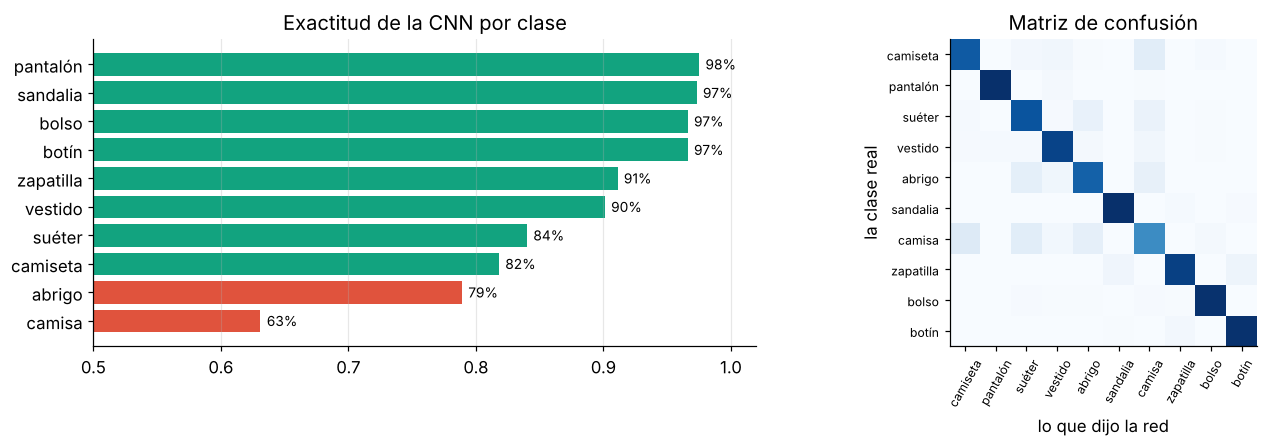

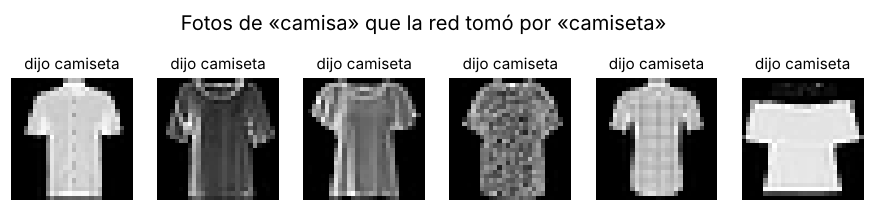

In [16]:
pred = cnn.predict(x_test, verbose=0).argmax(axis=1)                # the class with the highest probability
matriz = np.zeros((10, 10), dtype=int)
for real, dijo in zip(y_test, pred):
    matriz[real, dijo] += 1                                         # row = real class, column = prediction

por_clase = matriz.diagonal() / matriz.sum(axis=1)
fuera = matriz.copy(); np.fill_diagonal(fuera, 0)
r, c = np.unravel_index(fuera.argmax(), fuera.shape)
print(f"La confusión más frecuente: {matriz[r, c]} de {matriz[r].sum()} fotos de «{CLASES[r]}» las tomó por «{CLASES[c]}»")

orden = np.argsort(por_clase)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
axs[0].barh([CLASES[k] for k in orden], por_clase[orden], color=[CORAL if por_clase[k] < 0.8 else MENTA for k in orden])
for n, k in enumerate(orden): axs[0].text(por_clase[k] + 0.005, n, f"{por_clase[k]:.0%}", va="center", fontsize=9)
axs[0].set_xlim(0.5, 1.02); axs[0].set_title("Exactitud de la CNN por clase"); axs[0].grid(axis="y", alpha=0)
axs[1].imshow(matriz, cmap="Blues"); axs[1].set_xticks(range(10)); axs[1].set_yticks(range(10))
axs[1].set_xticklabels(CLASES, rotation=60, fontsize=8); axs[1].set_yticklabels(CLASES, fontsize=8)
axs[1].set_xlabel("lo que dijo la red"); axs[1].set_ylabel("la clase real"); axs[1].set_title("Matriz de confusión"); axs[1].grid(False)
plt.tight_layout(); plt.show()

errores = np.where((y_test == r) & (pred == c))[0][:6]
fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for ax, k in zip(axs, errores): ver(x_test[k], ax, f"dijo {CLASES[c]}")
plt.suptitle(f"Fotos de «{CLASES[r]}» que la red tomó por «{CLASES[c]}»", y=1.08); plt.show()

**Qué deberías ver:** la confusión más frecuente es **camisa tomada por camiseta**: alrededor de **129 de 1 000** camisas. La camisa es la clase más difícil (alrededor de **63 %**), seguida de abrigo y camiseta; pantalón, bolso, botín y sandalia pasan del 96 %. En las fotos de los errores verás camisas de manga corta que, a 28 × 28 píxeles, se parecen muchísimo a una camiseta: a veces ni una persona las distingue.

**Léelo así:** la exactitud total (87.7 %) esconde que hay clases fáciles y una muy difícil. Si tu proyecto dependiera de distinguir camisas, el 87.7 % no te diría lo importante.

### 💭 Para pensar

**1.** ¿Qué información da la matriz de confusión que la exactitud total no da?

<details><summary>Ver respuesta</summary>

**Qué** se confunde con **qué**: aquí, camisas con camisetas (y abrigos con suéteres). La exactitud total mezcla todas las clases en un solo número.
</details>

**2.** ¿Se te ocurre algo que ayudaría a distinguir camisas de camisetas?

<details><summary>Ver respuesta</summary>

Más **resolución** (a 28 × 28 se pierden botones y cuellos), más ejemplos difíciles, o una red más grande. Lo primero es mirar los errores, como hicimos: muchas veces el problema está en los datos.
</details>

---
## Resumen en 5 líneas
1. Una **imagen** es una tabla de números: 28 × 28 × 1 = 784 brillos entre 0 y 1.
2. Un **filtro** de 3 × 3 es una lupa que recorre la foto y responde fuerte donde encuentra su patrón; el resultado es un **mapa de activación**.
3. La **CNN** usa el **mismo filtro en toda la foto** (comparte pesos) y el **pooling** resume: 12 810 parámetros contra 101 770 de la densa, y un poco más de exactitud (87.7 % contra 86.7 %).
4. Con 10 clases, la salida es **softmax**: 10 probabilidades que suman 1.
5. **Cada arquitectura es una suposición**: la densa no usa la vecindad (le da igual mezclar píxeles); la CNN sí (aguanta mejor que la prenda se corra 2 píxeles).

---
## 🏁 Para comprobar que entendiste
Responde cada pregunta **antes** de abrir la respuesta. Si fallas alguna, vuelve a la parte indicada.

### 💭 Preguntas

**1.** ¿Qué forma tiene `x_train` después de prepararlo, y qué significa cada número?

<details><summary>Ver respuesta</summary>

`(60000, 28, 28, 1)`: 60 000 fotos, 28 de alto, 28 de ancho y **1 canal** (blanco y negro). (Parte 0)
</details>

**2.** Un filtro de borde vertical pasa por una zona de fondo, donde todo vale 0. ¿Qué anota en el mapa?

<details><summary>Ver respuesta</summary>

**0**: no hay cambio de brillo entre izquierda y derecha. (Parte 1)
</details>

**3.** Si la foto mide 28 × 28 y el filtro 3 × 3, ¿qué tamaño tiene el mapa? ¿Por qué no 28 × 28?

<details><summary>Ver respuesta</summary>

**26 × 26** (28 − 3 + 1): la ventana de 3 × 3 no puede salirse de la foto, así que hay 26 posiciones por fila y 26 por columna. (Partes 1 y 3)
</details>

**4.** ¿Por qué la primera capa de la densa tiene 100 480 parámetros?

<details><summary>Ver respuesta</summary>

Cada una de las 128 neuronas tiene un peso por cada uno de los 784 píxeles, más su sesgo: 784 × 128 + 128 = **100 480**. (Parte 2)
</details>

**5.** ¿Cuántos parámetros tiene una capa `Conv2D(16, 3)` sobre una foto de 1 canal? ¿Y si la foto fuera de 1 000 × 1 000?

<details><summary>Ver respuesta</summary>

16 × (3·3·1 + 1) = **160**, sea cual sea el tamaño de la foto: los filtros se reutilizan en todas las posiciones. (Parte 3)
</details>

**6.** ¿Qué hace `MaxPooling2D(2)` con una ventana que tiene los números 0.1, 0.9, 0.3 y 0.0?

<details><summary>Ver respuesta</summary>

Se queda con **0.9**, el más grande. Y el mapa completo queda de la mitad de alto y de ancho. (Parte 3)
</details>

**7.** ¿Qué devuelve la capa de salida con softmax para una foto, y cuánto suman sus números?

<details><summary>Ver respuesta</summary>

**10 probabilidades**, una por clase, que **suman 1**. La red elige la más grande. (Partes 2 y 4)
</details>

**8.** Con la prenda movida 2 píxeles, ¿qué red aguanta mejor y por qué?

<details><summary>Ver respuesta</summary>

La **CNN** (≈ 75 % contra ≈ 57 %): busca el mismo patrón en cualquier posición y el pooling tolera corrimientos pequeños. Para la densa, cada píxel tiene su propio peso. (Parte 5)
</details>

**9.** Al mezclar los píxeles (igual en todas las fotos), la densa da lo mismo y la CNN baja. ¿Qué nos dice eso de cada red?

<details><summary>Ver respuesta</summary>

Que la densa **no usa** la vecindad (supone que todo se relaciona con todo) y la CNN **sí** (supone que lo cercano importa). Cada arquitectura es una **suposición** sobre los datos. (Parte 5)
</details>

**10.** La CNN tiene 87.7 % de exactitud. ¿Por qué no basta ese número para saber si sirve?

<details><summary>Ver respuesta</summary>

Porque esconde clases muy distintas: camisa ≈ 63 % y pantalón ≈ 98 %. La matriz de confusión muestra **qué** confunde: camisas con camisetas. (Parte 6)
</details>

---
### 🧪 Experimento 3 (opcional): ¿cuántos filtros necesita?
📽 Lámina 23

**La pregunta:** la CNN usó 16 filtros en la primera capa y 32 en la segunda. ¿Y si usamos menos, o más?

**Qué hace este código:**
- `filtros = 16` decide los filtros de la primera capa; la segunda usa el doble.
- Arma la misma CNN con ese número, la entrena con las mismas reglas (5 épocas) y muestra parámetros, tiempo y exactitud.

🔮 **Antes de ejecutar (con `filtros = 4`):** ¿cuántos parámetros crees que tendrá? ¿Bajará mucho la exactitud?

In [17]:
filtros = 16                                       # filters in the first layer   (🧪 try 4, then 32)

keras.utils.set_random_seed(SEED)
cnn_exp = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(filtros, 3, activation="relu"), layers.MaxPooling2D(2),
    layers.Conv2D(2 * filtros, 3, activation="relu"), layers.MaxPooling2D(2),
    layers.Flatten(), layers.Dense(10, activation="softmax"),
])
cnn_exp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_exp.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=0)
print(f"{filtros} y {2 * filtros} filtros · {cnn_exp.count_params():,} parámetros · exactitud en prueba: {cnn_exp.evaluate(x_test, y_test, verbose=0)[1]:.1%}")

16 y 32 filtros · 12,810 parámetros · exactitud en prueba: 87.7%


**Qué deberías ver:** con `filtros = 16`, la misma CNN de la Parte 3: **12 810** parámetros y alrededor de **87.7 %**.

Con `filtros = 4`: **2 346** parámetros y alrededor de **82.8 %**: con 5 veces menos parámetros pierde 5 puntos. Con `8`: 5 258 parámetros y ≈ 86.2 %. Con `32`: **34 826** parámetros (casi el triple) y ≈ **88.1 %**: apenas 0.4 puntos más que con 16.

🧪 **Experimenta:** cambia `filtros = 16` por `4` y ejecuta otra vez; después prueba `32`. Compara parámetros y exactitud: ¿vale la pena el triple de parámetros?

### 💭 Para pensar

**1.** Si con 32 filtros la exactitud sube muy poco, ¿cuál red prefieres?

<details><summary>Ver respuesta</summary>

En general, la más **pequeña** que funcione bien: aprende más rápido, ocupa menos memoria y tiene menos riesgo de memorizar. Como siempre, hay que confirmarlo con el examen final.
</details>

**2.** ¿Qué otro valor cambiarías después, uno a la vez?

<details><summary>Ver respuesta</summary>

Por ejemplo, el tamaño del filtro (`3` → `5`), quitar un pooling o entrenar más épocas. **Uno a la vez**, para saber qué causó el cambio: es el experimento controlado de la semana 1.
</details>

---
**¿Te quedó alguna duda?** Repasa las slides interactivas y la guía de estudio desde la página del curso (Semana 2). En el Tema 2 la pregunta cambia: **¿cómo lee una red una secuencia?** Lee antes la lectura de tendencia, «¿El regreso de las redes recurrentes?».